In [44]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/dengue_clean .csv", parse_dates=["date"])
df["month_num"] = df["date"].dt.month
df.head()

,division,year,month,pollution,density,infected,death,temperature,humidity,pressure,class,date,death_rate,month_num
0,Dhaka,2020,January,High,High,88,0,19.0,0.80,1017.0,Medium,2020-01-01,0.0,1
1,Dhaka,2020,February,High,High,17,0,23.0,0.63,1014.0,Low,2020-02-01,0.0,2
2,Dhaka,2020,March,High,High,21,0,27.0,0.55,1011.0,Low,2020-03-01,0.0,3
3,Dhaka,2020,April,High,High,20,0,28.0,0.70,1009.0,Low,2020-04-01,0.0,4
4,Dhaka,2020,May,High,High,10,0,29.0,0.80,1005.0,Low,2020-05-01,0.0,5


            infected  death
division                   
Dhaka         344039   2159
Chattogram     90436    297
Barishal       75727    330
Khulna         48049    139
Rajshahi       30451     88
Mymensingh     19138     75
Rangpur        10309     15
Sylhet          3160      3


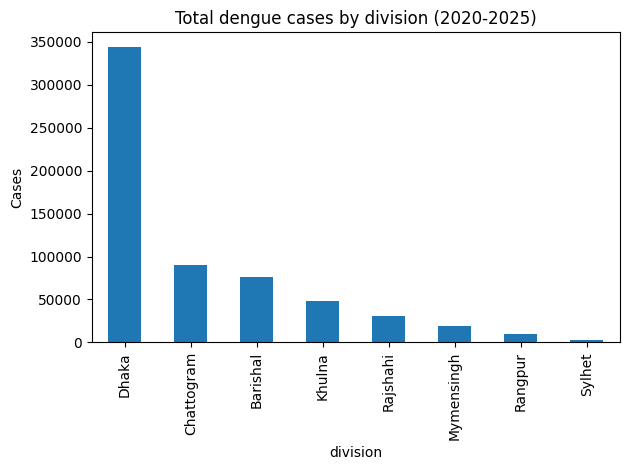

In [45]:
by_div = df.groupby("division")[["infected", "death"]].sum().sort_values("infected", ascending=False)
print(by_div)

by_div["infected"].plot(kind="bar", title="Total dengue cases by division (2020-2025)")
plt.ylabel("Cases")
plt.tight_layout()
plt.savefig("cases_by_division.png")
plt.show()

division
Dhaka         0.63
Barishal      0.44
Mymensingh    0.39
Chattogram    0.33
Khulna        0.29
Rajshahi      0.29
Rangpur       0.15
Sylhet        0.09
Name: death_rate_%, dtype: float64


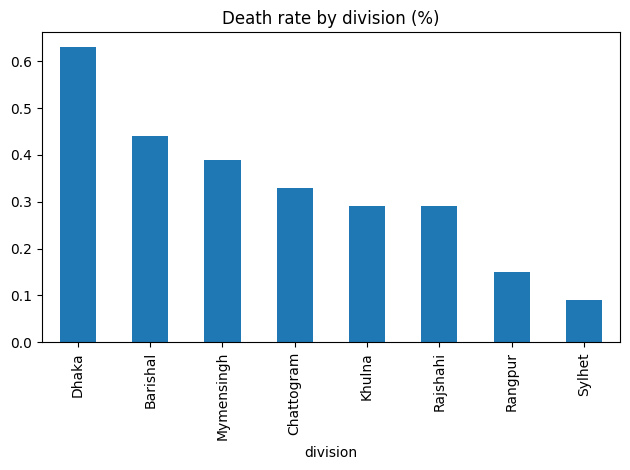

In [46]:
by_div["death_rate_%"] = (by_div["death"] / by_div["infected"] * 100).round(2)
print(by_div["death_rate_%"].sort_values(ascending=False))

by_div["death_rate_%"].sort_values(ascending=False).plot(kind="bar", title="Death rate by division (%)")
plt.tight_layout()
plt.savefig("death_rate_by_division.png")
plt.show()

month_num
1       3138
2        953
3        816
4       1407
5       3670
6      13743
7      59672
8     100280
9     131359
10    151724
11    119557
12     34990
Name: infected, dtype: int64


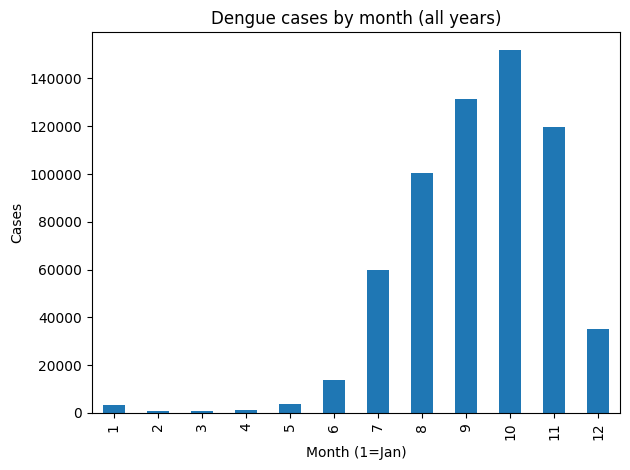

In [47]:
by_month = df.groupby("month_num")["infected"].sum()
print(by_month)

by_month.plot(kind="bar", title="Dengue cases by month (all years)")
plt.xlabel("Month (1=Jan)")
plt.ylabel("Cases")
plt.tight_layout()
plt.savefig("cases_by_month.png")
plt.show()

      infected  death
year                 
2020      1406      7
2021     28428    106
2022     65081    282
2023    323971   1697
2024    101252    575
2025    101171    439


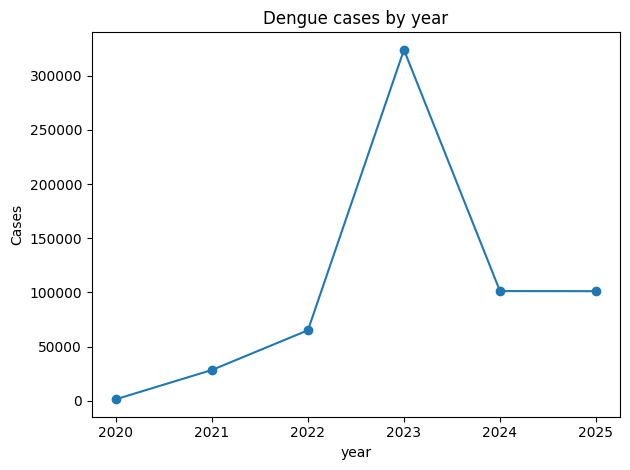

In [48]:
by_year = df.groupby("year")[["infected", "death"]].sum()
print(by_year)

by_year["infected"].plot(kind="line", marker="o", title="Dengue cases by year")
plt.ylabel("Cases")
plt.tight_layout()
plt.savefig("cases_by_year.png")
plt.show()

             infected  death  temperature  humidity  pressure
infected         1.00   0.96         0.11      0.04     -0.05
death            0.96   1.00         0.07     -0.01     -0.02
temperature      0.11   0.07         1.00      0.15     -0.86
humidity         0.04  -0.01         0.15      1.00     -0.40
pressure        -0.05  -0.02        -0.86     -0.40      1.00


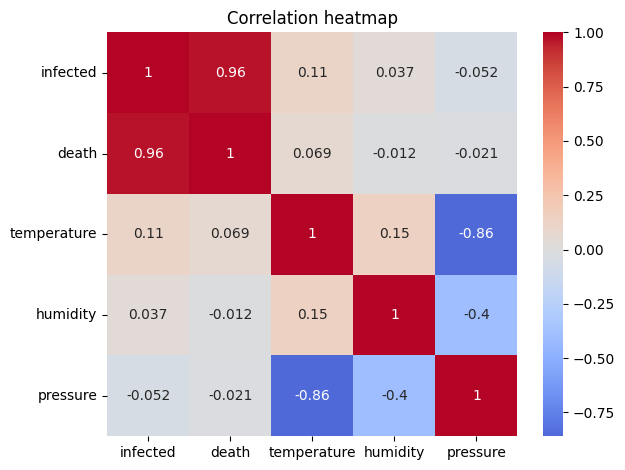

In [49]:
cols = ["infected", "death", "temperature", "humidity", "pressure"]
print(df[cols].corr().round(2))

sns.heatmap(df[cols].corr(), annot=True, cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("correlation_heatmap.png")
plt.show()

In [50]:
import sqlite3
df["month_num"] = df["date"].dt.month
conn = sqlite3.connect(":memory:")
df.to_sql("dengue", conn, index=False, if_exists="replace")

def q(sql):
    return pd.read_sql(sql, conn)

In [51]:
q("""
-- a1: Prothom 5 row dekho
SELECT * FROM dengue LIMIT 5
""")

,division,year,month,pollution,density,infected,death,temperature,humidity,pressure,class,date,death_rate,month_num
0,Dhaka,2020,January,High,High,88,0,19.0,0.80,1017.0,Medium,2020-01-01 00:00:00,0.0,1
1,Dhaka,2020,February,High,High,17,0,23.0,0.63,1014.0,Low,2020-02-01 00:00:00,0.0,2
2,Dhaka,2020,March,High,High,21,0,27.0,0.55,1011.0,Low,2020-03-01 00:00:00,0.0,3
3,Dhaka,2020,April,High,High,20,0,28.0,0.70,1009.0,Low,2020-04-01 00:00:00,0.0,4
4,Dhaka,2020,May,High,High,10,0,29.0,0.80,1005.0,Low,2020-05-01 00:00:00,0.0,5


In [52]:
q("""
-- a2: Koyta row?
SELECT COUNT(*) AS total_rows FROM dengue
""")

,total_rows
0,576


In [53]:
q("""
-- a3: Kon kon division ache?
SELECT DISTINCT division FROM dengue
""")

,division
0,Dhaka
1,Mymensingh
2,Chattogram
3,Barishal
4,Sylhet
5,Khulna
6,Rajshahi
7,Rangpur


In [54]:
q("""
SELECT DISTINCT division, LENGTH(division) AS name_length FROM dengue
""")

,division,name_length
0,Dhaka,5
1,Mymensingh,10
2,Chattogram,10
3,Barishal,8
4,Sylhet,6
5,Khulna,6
6,Rajshahi,8
7,Rangpur,7


In [55]:
q("""
-- c1: Which division has the most cases and highest death rate?
SELECT division,
       SUM(infected) AS cases,
       SUM(death) AS deaths,
       ROUND(100.0 * SUM(death) / SUM(infected), 2) AS death_rate_pct
FROM dengue
GROUP BY division
ORDER BY cases DESC
""")

,division,cases,deaths,death_rate_pct
0,Dhaka,344039,2159,0.63
1,Chattogram,90436,297,0.33
2,Barishal,75727,330,0.44
3,Khulna,48049,139,0.29
4,Rajshahi,30451,88,0.29
5,Mymensingh,19138,75,0.39
6,Rangpur,10309,15,0.15
7,Sylhet,3160,3,0.09


In [56]:
q("""
-- c2: In which months do cases peak, and what is the climate like?
SELECT month_num,
       SUM(infected) AS cases,
       ROUND(AVG(temperature), 1) AS avg_temp,
       ROUND(AVG(humidity), 2) AS avg_humidity
FROM dengue
GROUP BY month_num
ORDER BY month_num
""")

,month_num,cases,avg_temp,avg_humidity
0,1,3138,18.7,0.78
1,2,953,22.3,0.67
2,3,816,26.0,0.65
3,4,1407,28.8,0.68
4,5,3670,29.3,0.76
5,6,13743,29.6,0.82
6,7,59672,29.6,0.84
7,8,100280,29.2,0.85
8,9,131359,29.4,0.82
9,10,151724,27.9,0.81


In [57]:
q("""
-- Practice: How many cases and deaths per pollution level?
SELECT pollution,
       SUM(infected) AS cases,
       SUM(death) AS deaths
FROM dengue
GROUP BY pollution
ORDER BY cases DESC
""")

,pollution,cases,deaths
0,High,434475,2456
1,Low,78887,333
2,Medium,78500,227
3,Very Low,29447,90


In [58]:
q("""
-- d1: Which divisions have more than 50,000 total cases?
SELECT division,
       SUM(infected) AS cases
FROM dengue
GROUP BY division
HAVING SUM(infected) > 50000
ORDER BY cases DESC
""")

,division,cases
0,Dhaka,344039
1,Chattogram,90436
2,Barishal,75727


In [59]:
q("""
-- d1b: Since 2023, which divisions had more than 100 deaths?
SELECT division,
       SUM(infected) AS cases,
       SUM(death) AS deaths
FROM dengue
WHERE year >= 2023
GROUP BY division
HAVING SUM(death) > 100
ORDER BY deaths DESC
""")

,division,cases,deaths
0,Dhaka,284726,1907
1,Barishal,68573,303
2,Chattogram,76309,215
3,Khulna,42570,125


In [60]:
q("""
-- d2: Which 5 division-months had the most cases?
SELECT division, date, infected, death
FROM dengue
ORDER BY infected DESC
LIMIT 5
""")

,division,date,infected,death
0,Dhaka,2023-08-01 00:00:00,40615,293
1,Dhaka,2023-10-01 00:00:00,40615,256
2,Dhaka,2023-09-01 00:00:00,40533,265
3,Dhaka,2023-07-01 00:00:00,27987,164
4,Dhaka,2023-11-01 00:00:00,18025,162


In [61]:
q("""
-- d3: In how many months did each division exceed 1,000 cases?
SELECT division,
       COUNT(*) AS months_over_1000
FROM dengue
WHERE infected > 1000
GROUP BY division
ORDER BY months_over_1000 DESC
""")

,division,months_over_1000
0,Dhaka,31
1,Chattogram,23
2,Barishal,17
3,Khulna,13
4,Rajshahi,10
5,Mymensingh,7
6,Rangpur,3


In [62]:
q("""
-- Practice 1: Which years had more than 50,000 total cases?
SELECT year,
       SUM(infected) AS cases
FROM dengue
GROUP BY year
HAVING SUM(infected) > 50000
ORDER BY year
""")

,year,cases
0,2022,65081
1,2023,323971
2,2024,101252
3,2025,101171


In [63]:
q("""
-- Practice 2: Top 3 division-months by deaths
SELECT division, date, infected, death
FROM dengue
ORDER BY death DESC
LIMIT 3
""")

,division,date,infected,death
0,Dhaka,2023-08-01 00:00:00,40615,293
1,Dhaka,2023-09-01 00:00:00,40533,265
2,Dhaka,2023-10-01 00:00:00,40615,256


In [64]:
q("""
-- Practice 3: Months, avg temperature and humidity per class
SELECT class,
       COUNT(*) AS months,
       ROUND(AVG(temperature), 1) AS avg_temp,
       ROUND(AVG(humidity), 2) AS avg_humidity
FROM dengue
GROUP BY class
ORDER BY months DESC
""")

,class,months,avg_temp,avg_humidity
0,High,168,27.2,0.79
1,Low,149,25.9,0.76
2,Very Low,130,26.2,0.73
3,Medium,129,25.7,0.78


In [66]:
q("""
-- e1: What share of all cases does each division account for?
SELECT division,
       SUM(infected) AS cases,
       ROUND(100.0 * SUM(infected) / (SELECT SUM(infected) FROM dengue), 1) AS share_pct
FROM dengue
GROUP BY division
ORDER BY cases DESC
""")

,division,cases,share_pct
0,Dhaka,344039,55.4
1,Chattogram,90436,14.6
2,Barishal,75727,12.2
3,Khulna,48049,7.7
4,Rajshahi,30451,4.9
5,Mymensingh,19138,3.1
6,Rangpur,10309,1.7
7,Sylhet,3160,0.5


In [67]:
q("""
-- e2: What share of cases happens in Aug-Nov vs the rest of the year?
SELECT CASE WHEN month_num BETWEEN 8 AND 11 THEN 'Aug-Nov'
            ELSE 'Other months' END AS period,
       SUM(infected) AS cases,
       ROUND(100.0 * SUM(infected) / (SELECT SUM(infected) FROM dengue), 1) AS share_pct
FROM dengue
GROUP BY period
""")

,period,cases,share_pct
0,Aug-Nov,502920,80.9
1,Other months,118389,19.1


In [68]:
q("""
-- e3: Classify divisions by total case volume
SELECT division,
       SUM(infected) AS cases,
       CASE WHEN SUM(infected) >= 100000 THEN 'Very High'
            WHEN SUM(infected) >= 50000  THEN 'High'
            WHEN SUM(infected) >= 10000  THEN 'Medium'
            ELSE 'Low' END AS burden_level
FROM dengue
GROUP BY division
ORDER BY cases DESC
""")

,division,cases,burden_level
0,Dhaka,344039,Very High
1,Chattogram,90436,High
2,Barishal,75727,High
3,Khulna,48049,Medium
4,Rajshahi,30451,Medium
5,Mymensingh,19138,Medium
6,Rangpur,10309,Medium
7,Sylhet,3160,Low


-- Q1: How many rows are in the table?
SELECT COUNT(*) AS total_rows FROM dengue;

-- Q2: Which division has the most cases and the highest death rate?
SELECT division,
       SUM(infected) AS cases,
       SUM(death) AS deaths,
       ROUND(100.0 * SUM(death) / SUM(infected), 2) AS death_rate_pct
FROM dengue
GROUP BY division
ORDER BY cases DESC;

-- Q3: In which months do cases peak, and what is the climate like?
SELECT month_num,
       SUM(infected) AS cases,
       ROUND(AVG(temperature), 1) AS avg_temp,
       ROUND(AVG(humidity), 2) AS avg_humidity
FROM dengue
GROUP BY month_num
ORDER BY month_num;

-- Q4: How did cases and deaths change year by year?
SELECT year, SUM(infected) AS cases, SUM(death) AS deaths
FROM dengue
GROUP BY year
ORDER BY year;

-- Q5: Which divisions have more than 50,000 total cases?
SELECT division, SUM(infected) AS cases
FROM dengue
GROUP BY division
HAVING SUM(infected) > 50000
ORDER BY cases DESC;

-- Q6: Which 5 division-months had the most cases?
SELECT division, date, infected, death
FROM dengue
ORDER BY infected DESC
LIMIT 5;

-- Q7: What share of all cases does each division account for?
SELECT division,
       SUM(infected) AS cases,
       ROUND(100.0 * SUM(infected) / (SELECT SUM(infected) FROM dengue), 1) AS share_pct
FROM dengue
GROUP BY division
ORDER BY cases DESC;

-- Q8: What share of cases happens in Aug-Nov vs the rest of the year?
SELECT CASE WHEN month_num BETWEEN 8 AND 11 THEN 'Aug-Nov'
            ELSE 'Other months' END AS period,
       SUM(infected) AS cases,
       ROUND(100.0 * SUM(infected) / (SELECT SUM(infected) FROM dengue), 1) AS share_pct
FROM dengue
GROUP BY period;